# 03 · What makes customers buy, and whom to call first

The two remaining questions:

1. **What makes customers buy?** Which features should the bank focus on?
2. **Which customer segments should the bank prioritise?**

We answer them with three tools, each answering a different question:

| Tool | Question it answers |
| --- | --- |
| Permutation importance | *How much* does the model rely on each column? |
| Partial dependence | In *which direction* does a column push the chance of buying, all else equal? |
| Segment tree | *Which groups* of customers buy more, as simple rules a person can follow? |

The whole notebook takes about 2 minutes to run.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import partial_dependence

from term_deposit.config import (
    CALL_RESULT_FEATURES,
    FIGURES_DIR,
    FINAL_MODEL,
    NUMERIC,
    PROFILE_FEATURES,
    STAGES,
    TARGET,
)
from term_deposit.data import load_data
from term_deposit.evaluation import cv_scores, time_ordered_split
from term_deposit.insights import (
    permutation_importance_cv,
    segment_names,
    segment_tree,
    subscription_rates,
)
from term_deposit.models import get_candidates

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)

BLUE, ORANGE, AQUA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c3c2b7",
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "axes.labelcolor": "#52514e",
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
    }
)
STAGE_NAMES = {"pre_call": "Before the call", "post_call": "After the call"}

df = load_data()
y = df[TARGET]
candidates = get_candidates()

## 1. What do the models rely on?

**Permutation importance:** shuffle one column so it no longer matches its customers, and measure
how much worse the model ranks buyers (the drop in PR-AUC). A column the model ignores costs
nothing; a column it depends on costs a lot. It is measured on test folds the model never saw,
like every score in this project.

The columns fall into three groups, coloured in the chart:

- **Customer:** who the customer is (`PROFILE_FEATURES`: age, job, balance, loans, ...).
- **Calling:** when and how the bank calls (`month`, `day`, `contact`) and how often (`campaign`).
- **Call result:** `duration`, known only after the call.

In [2]:
importance = {
    stage: permutation_importance_cv(
        candidates[FINAL_MODEL[stage]].tuned(features), df[features], y
    )
    for stage, features in STAGES.items()
}
pd.concat(
    {STAGE_NAMES[stage]: folds.mean() for stage, folds in importance.items()}, axis=1
).sort_values("Before the call", ascending=False).round(3)

,Before the call,After the call
month,0.145,0.204
contact,0.104,0.086
day,0.061,0.137
housing,0.021,0.018
age,0.009,0.003
marital,0.007,0.009
balance,0.004,0.002
campaign,0.004,0.005
education,0.003,0.003
loan,0.001,0.001


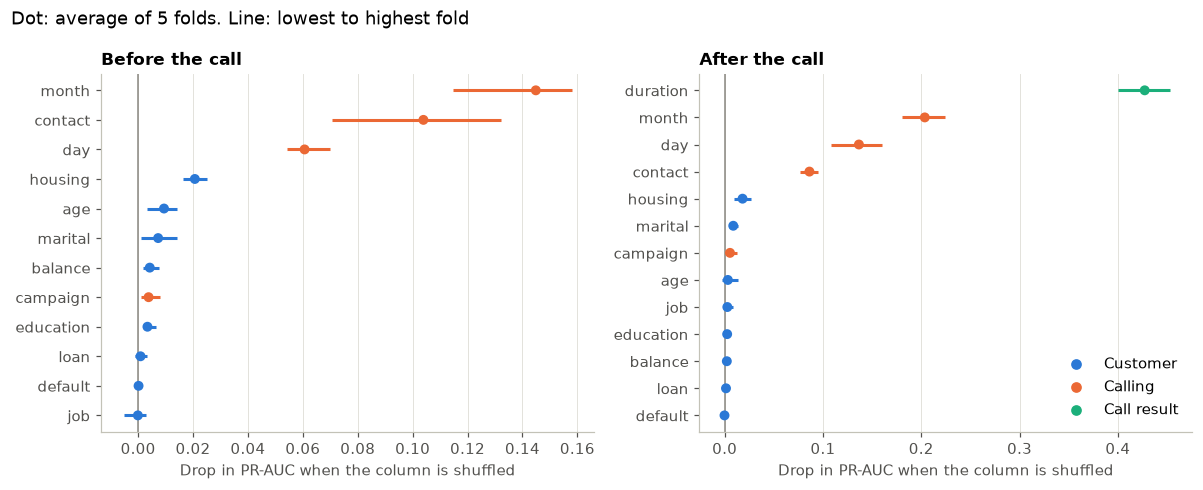

In [3]:
def group_color(column):
    if column in CALL_RESULT_FEATURES:
        return AQUA
    return BLUE if column in PROFILE_FEATURES else ORANGE


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (stage, folds) in zip(axes, importance.items(), strict=True):
    folds = folds[folds.mean().sort_values(ascending=False).index]
    rows = np.arange(folds.shape[1])
    colors = [group_color(column) for column in folds.columns]
    ax.hlines(rows, folds.min(), folds.max(), color=colors, linewidth=2)
    ax.scatter(folds.mean(), rows, color=colors, s=30, zorder=3)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_yticks(rows, folds.columns)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Drop in PR-AUC when the column is shuffled")
    ax.set_title(STAGE_NAMES[stage], loc="left")
for label, color in [("Customer", BLUE), ("Calling", ORANGE), ("Call result", AQUA)]:
    axes[1].scatter([], [], color=color, label=label)
axes[1].legend(frameon=False, loc="lower right")
fig.suptitle("Dot: average of 5 folds. Line: lowest to highest fold", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "importance.png")

**Findings:**

- **Before the call, timing matters most.** `month` (0.145), `contact` (0.104) and `day` (0.061)
  lead by far. Together, `month` and `day` pin down *which campaign days* went well; notebook 01
  showed that the same month name had very different success rates in different years, so this
  is about **when** the bank called, not a season that repeats.
- **Customer traits come next:** having a housing loan (0.021), age (0.009), marital status, balance
  and education.
- **After the call, `duration` dominates** (0.427): how engaged the conversation was is the
  strongest sign of a sale.
- **`job` scores about 0.** Its information is already carried by age (students are young,
  retirees are old). Permutation importance measures what a column adds *on top of* the others.

## 2. Customer traits alone

Timing is something the bank controls, but the brief asks about the **customers**. Here the same
kind of model sees only the customer's traits, the information in the customer list before any
campaign starts. Two questions: how much can it do, and which traits does it use?

In [4]:
profile_model = candidates[FINAL_MODEL["pre_call"]].tuned(PROFILE_FEATURES)
profile_scores = cv_scores(profile_model, df[PROFILE_FEATURES], y)
print(
    f"Customer traits only: PR-AUC {profile_scores['average_precision'].mean():.3f}, "
    f"ROC-AUC {profile_scores['roc_auc'].mean():.3f} (guessing: {y.mean():.3f} and 0.500)"
)
profile_importance = permutation_importance_cv(profile_model, df[PROFILE_FEATURES], y)
profile_importance.agg(["mean", "std"]).T.sort_values("mean", ascending=False).round(3)

Customer traits only: PR-AUC 0.138, ROC-AUC 0.625 (guessing: 0.072 and 0.500)


,mean,std
age,0.035,0.006
housing,0.020,0.004
balance,0.013,0.004
marital,0.008,0.004
education,0.008,0.003
loan,0.004,0.001
job,0.000,0.003
default,0.000,0.000


**Findings:** customer traits alone rank buyers about **twice as well as guessing** (PR-AUC 0.138
vs 0.072), roughly half of what the full model achieves with timing. The traits that matter, in
order: **age**, **housing loan**, **balance**, then marital status and education. Personal loan and
job add little; credit default adds nothing.

## 3. In which direction? Partial dependence

Importance says *how much*; partial dependence says *which way*. For each value of a column (for
example age 70), we set **every** customer to that value, keep everything else as it is, and
average the model's predicted chance of buying. The result is the effect of that column with the
others, including the calendar, held fixed.

This uses the production before-the-call model, trained on all customers. Its whole-number
columns are given as decimals, which `partial_dependence` requires.

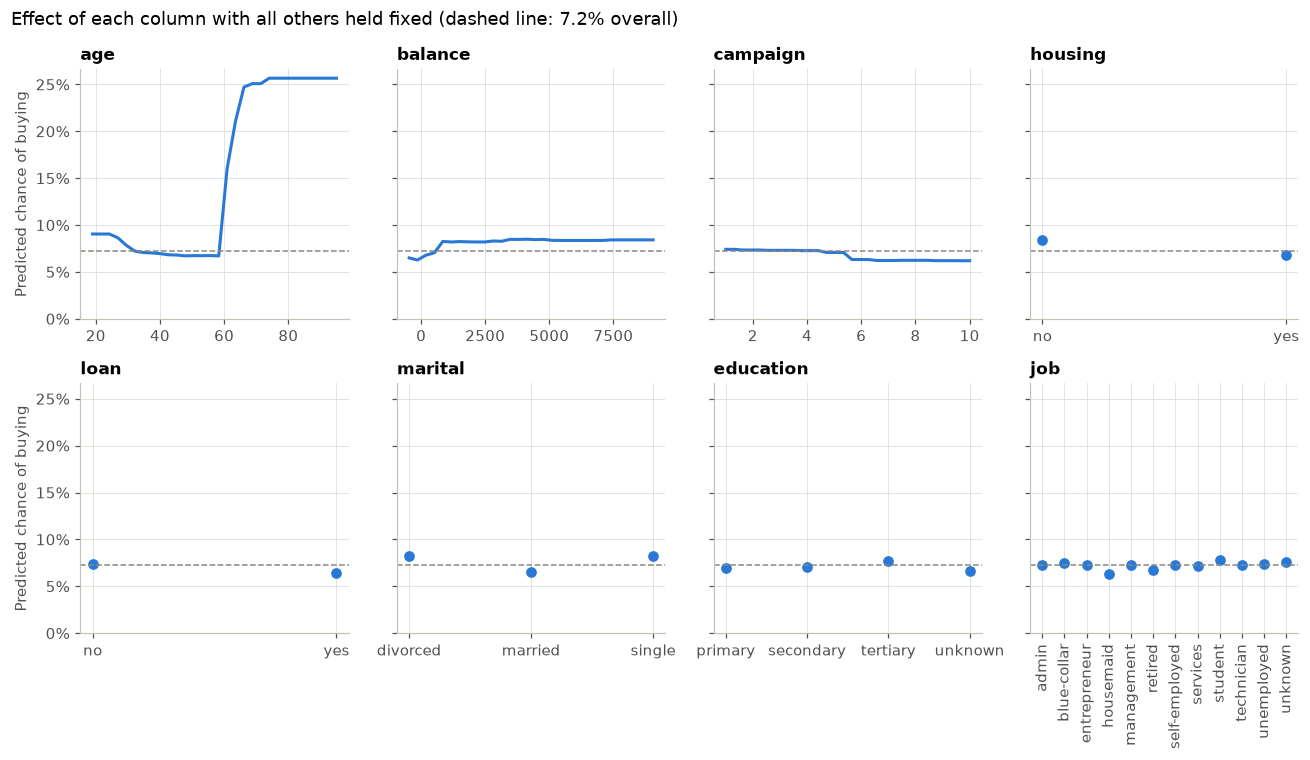

In [5]:
features = STAGES["pre_call"]
X = df[features].astype({column: "float64" for column in NUMERIC if column in features})
model = candidates[FINAL_MODEL["pre_call"]].tuned(features).fit(X, y).best_estimator_

numeric_panels = {"age": (0, 1), "balance": (0.02, 0.98), "campaign": (0, 0.97)}
category_panels = ["housing", "loan", "marital", "education", "job"]

fig, axes = plt.subplots(2, 4, figsize=(12, 7), sharey=True)
for ax, (column, percentiles) in zip(axes[0], numeric_panels.items(), strict=False):
    result = partial_dependence(model, X, [column], percentiles=percentiles, grid_resolution=30)
    ax.plot(result["grid_values"][0], result["average"][0], color=BLUE, linewidth=2)
    ax.set_title(column, loc="left")
category_axes = [axes[0, 3], *axes[1]]
for ax, column in zip(category_axes, category_panels, strict=True):
    result = partial_dependence(model, X, [column], categorical_features=[column])
    ax.plot(result["grid_values"][0], result["average"][0], "o", color=BLUE, markersize=6)
    ax.tick_params(axis="x", labelrotation=90 if column == "job" else 0)
    ax.set_title(column, loc="left")
for ax in axes.flat:
    ax.axhline(y.mean(), color=MUTED, linestyle="--", linewidth=1)
    ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
    ax.set_ylim(bottom=0)
axes[0, 0].set_ylabel("Predicted chance of buying")
axes[1, 0].set_ylabel("Predicted chance of buying")
fig.suptitle(
    "Effect of each column with all others held fixed (dashed line: 7.2% overall)",
    x=0.01,
    ha="left",
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "partial_dependence.png")

**Findings (all else equal):**

- **Age is the strongest customer driver, and it is about the over-60s.** The chance is flat at
  about 7% from 30 to 60, slightly higher under 25 (9%), and jumps to **over 20% from about 65**.
  Only 234 customers are over 60, so the size of the jump is uncertain, but its direction matches
  notebook 01 (39% of them bought).
- **Balance helps up to about €1,000** (6% at zero, 8% from €1,000), then levels off.
- **No housing loan:** 8.4% vs 6.8% with one; **no personal loan:** 7.4% vs 6.4%. Money tied up in
  loans is not free to lock away.
- **Single or divorced:** 8.2% vs 6.6% for married customers. **Tertiary education:** slightly higher.
- **Job is flat (6–8%):** once age is known, the job title adds little. Students and retirees buy
  more because of their age.
- **Calls:** the chance stays level for the first 5 calls and drops after that. Part of the steep
  fall seen in notebook 01 came from timing, not from the extra calls themselves.

These are what the model learned from the data: **associations, not proof of cause**. They say who
is more likely to buy, not that changing a customer's loan would change their answer.

## 4. Which segments to prioritise

A **segment** is a group of customers the bank can recognise in its customer list. We let a
shallow decision tree find them:

- **Only customer traits** (`PROFILE_FEATURES`), not timing, because a segment should describe
  people and still hold in the next campaign.
- **At most 3 questions deep**, so at most 8 segments, each a rule a person can read.
- **Every segment holds at least 2% of customers**, so it is big enough to plan a campaign around.
- **Learned on the earlier 80% of rows, checked on the later 20%.** A segment is only useful if
  it still stands out in a campaign the tree has not seen. Because the overall yes rate changed
  between the two periods (5.9% vs 12.5%), we compare **lift**: the segment's rate divided by its
  period's average. A lift of 2 means twice as likely as the average customer at that time.

In [6]:
((train, test),) = time_ordered_split(len(df))
earlier, later = df.iloc[train], df.iloc[test]
segments = segment_tree(PROFILE_FEATURES).fit(earlier[PROFILE_FEATURES], earlier[TARGET])


def segment_rates(part):
    """Customers, rate and lift of each segment in one period."""
    named = part.assign(segment=segment_names(segments, part[PROFILE_FEATURES]))
    table = subscription_rates(named, "segment", sort=False)
    return table.assign(lift=table["rate"] / part[TARGET].mean())


segment_table = pd.concat(
    {"earlier": segment_rates(earlier), "later": segment_rates(later)}, axis=1
)
summary = pd.DataFrame(
    {
        "share_of_customers": segment_table[[("earlier", "customers"), ("later", "customers")]].sum(
            axis=1
        )
        / len(df),
        "rate_earlier": segment_table[("earlier", "rate")],
        "rate_later": segment_table[("later", "rate")],
        "lift_earlier": segment_table[("earlier", "lift")],
        "lift_later": segment_table[("later", "lift")],
    }
)
summary["holds_up"] = (summary["lift_earlier"] > 1) == (summary["lift_later"] > 1)
summary = summary.sort_values("lift_earlier", ascending=False)
summary.round(3)

,share_of_customers,rate_earlier,rate_later,lift_earlier,lift_later,holds_up
segment,,,,,,
marital is not married and balance ≥ 617 and housing: no,0.061,0.121,0.325,2.042,2.599,True
"marital is married and balance ≥ 1,162 and age ≥ 57",0.021,0.096,0.262,1.625,2.095,True
marital is not married and balance ≤ 616 and age ≤ 30,0.064,0.079,0.163,1.331,1.303,True
marital is not married and balance ≥ 617 and housing: yes,0.091,0.078,0.104,1.320,0.830,False
"marital is married and balance ≥ 1,162 and age ≤ 56",0.153,0.061,0.146,1.035,1.169,True
marital is not married and balance ≤ 616 and age ≥ 31,0.174,0.056,0.112,0.949,0.895,True
"marital is married and balance ≤ 1,161 and housing: no",0.166,0.051,0.263,0.856,2.102,False
"marital is married and balance ≤ 1,161 and housing: yes",0.269,0.037,0.066,0.618,0.531,True


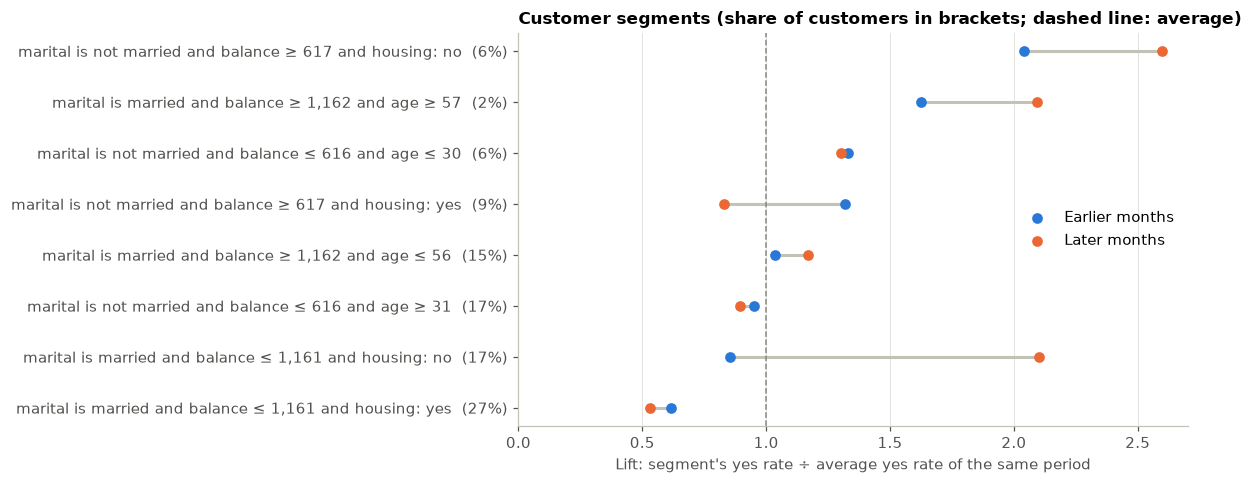

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
rows = np.arange(len(summary))
ax.hlines(rows, summary["lift_earlier"], summary["lift_later"], color="#c3c2b7", linewidth=2)
ax.scatter(summary["lift_earlier"], rows, color=BLUE, s=36, zorder=3, label="Earlier months")
ax.scatter(summary["lift_later"], rows, color=ORANGE, s=36, zorder=3, label="Later months")
ax.axvline(1, color=MUTED, linestyle="--", linewidth=1)
labels = [
    f"{rule}  ({share:.0%})"
    for rule, share in zip(summary.index, summary["share_of_customers"], strict=True)
]
ax.set_yticks(rows, labels)
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Lift: segment's yes rate ÷ average yes rate of the same period")
ax.legend(frameon=False, loc="center right")
ax.set_title("Customer segments (share of customers in brackets; dashed line: average)", loc="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "segments.png")

**Findings:**

| Priority | Segment | Share of customers | Lift: earlier → later |
| --- | --- | --- | --- |
| **1** | Not married, balance ≥ €617, **no housing loan** | 6% | **2.0× → 2.6×** |
| **2** | Married, **aged 57+**, balance ≥ €1,162 | 2% | **1.6× → 2.1×** |
| **3** | Not married, **aged 30 or under**, balance ≤ €616 | 6% | 1.3× → 1.3× |
| Last | Married, balance ≤ €1,161, **with a housing loan** | 27% | 0.6× → 0.5× |

- Segments 1–3 stand out **in both periods**, so they are safe to prioritise in the next campaign.
- The lowest segment is the largest: about a quarter of all customers buy at half the average rate.
  They are the first candidates for a cheaper channel (letter, e-mail) instead of a call.
- Two segments **flip** between periods (`holds_up` is False): not married with a housing loan, and
  married without one but with a low balance. They are not reliable enough to act on.
- The over-60s (section 3: over 20% chance) are too few here (234 customers, under 1%) to form a
  2% segment, but whenever they appear in the list they belong near the top, which the model's
  score already does.

## 5. Answers to the brief

**What makes customers buy? Which features to focus on:**

1. **When and how the bank calls** matters most before the call: the campaign period (`month`,
   `day`) and reaching customers on their mobile (`contact`). Because month effects changed from
   one year to the next, the bank should not hard-code "call in March"; it should **retrain on the
   latest campaign** so the model learns the current timing.
2. **During the call, engagement** (`duration`) is the strongest sign of a sale. It is a signal,
   not a lever: long, engaged conversations should be followed up quickly (the after-call model's
   callback list).
3. **Among customer traits:** **age** (over 60 especially, and under 25), **no housing loan**,
   **balance above about €1,000**, then **single or divorced** and **tertiary education**. Job adds
   little once age is known.
4. **Fewer repeat calls:** the chance drops after about 5 calls to the same customer, which
   suggests capping attempts there.

**Which segments to prioritise:** segments 1–3 above, in that order, and the over-60s wherever they
appear. Call the largest low segment (married, low balance, housing loan) last, or reach it
through a cheaper channel.

**How this is used together with notebook 02:** the model's score orders the daily call list
customer by customer; the segments give marketing simple groups to plan offers and messages for;
and the drivers tell the bank what to watch when a new campaign is designed.